# Problem 3.3

Consider the following mathematical model:

$$\frac{u_1^2}{4} + u_2^2 = 1$$

$$4 u_1 u_2 = \pi$$

$$f = 4(u_1 + u_2).$$

Solve this model by hand. Write these equations in residual form and use a numerical solver to obtain the same solution.

In [89]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

Using Newtons method:

Residual form: only two residuals with f as the function output at the end

$$r_1 = \frac{1}{4} \cdot u_1^2 + u_2^2 - 1 = 0$$
$$r_2 = 4 \cdot u_1 \cdot u_2 - \pi = 0$$

Jacobian:
$$
J = \begin{bmatrix}
\frac{1}{2} \cdot u_1 & 2 \cdot u_2 \\
4 \cdot u_2           & 4 \cdot u_1
\end{bmatrix}
$$

Linear system:

$$J \cdot \Delta u = -r$$

Starting value:

$$ u^{(0)} = (1,1)$$

Hand calculations: (stopped, too much of a hassle with latex formating, no real learning effect for me)

$J^{(1)} = \begin{bmatrix} 0.5 & 2 \\ 4 & 4 \end{bmatrix}$,
$r^{(1)} = \begin{bmatrix} 0.25 \\ 0.858 \end{bmatrix}$,
$\Delta u^{(1)} = J^{(1)-1} \cdot r^{(1)} = - \frac{1}{6} \begin{bmatrix} 4 & -2 \\ -4 & 0.5 \end{bmatrix} \cdot \begin{bmatrix} 0.5 \\ 0.858 \end{bmatrix}= \begin{bmatrix} 0.0406 \\ -1.112 \end{bmatrix}$,
$u^{(1)} = u^{(1)} + \Delta u^{(0)} = \begin{bmatrix} 1 \\ 1 \end{bmatrix} + \begin{bmatrix} 0.0406 \\ -0.0255 \end{bmatrix} = \begin{bmatrix} 1.0406 \\ 0.9745 \end{bmatrix}$




In [90]:
# machine solver

def residuals(u):
    u1, u2 = u
    return np.array([
        0.25 * u1**2 + u2**2 - 1,
        4 * u1 * u2 - np.pi,
    ])

def jacobian(u):
    u1, u2 = u
    return np.array([
        [0.5 * u1, 2 * u2],
        [4 * u2,   4 * u1],
    ])

def func(u):
    u1, u2 = u
    return 4*(u1 + u2)

def print_u(u):
    u1, u2 = u
    print(f"u1: {u1:.6f}, u2: {u2:.6f}, f(u): {func(u):.6f}")

def solve_system(u0):
    u = u0
    #print_u(u)
    for i in range(10):
        r = residuals(u)
        J = jacobian(u)
        du = np.linalg.solve(J, -r)
        if np.linalg.norm(du) < 1e-7: # convergence criterion
            #print("converged")
            break
        u = u + du
    print_u(u)
    return u

u1 = solve_system(np.array([2.0, 0.5]))
u2 = solve_system(np.array([1.0, 1.0]))
u3 = solve_system(np.array([-1.0, -1.0]))
u4 = solve_system(np.array([-2.0, -0.5]))



u1: 1.799439, u2: 0.436468, f(u): 8.943630
u1: 0.872937, u2: 0.899720, f(u): 7.090625
u1: -0.872937, u2: -0.899720, f(u): -7.090625
u1: -1.799439, u2: -0.436468, f(u): -8.943630


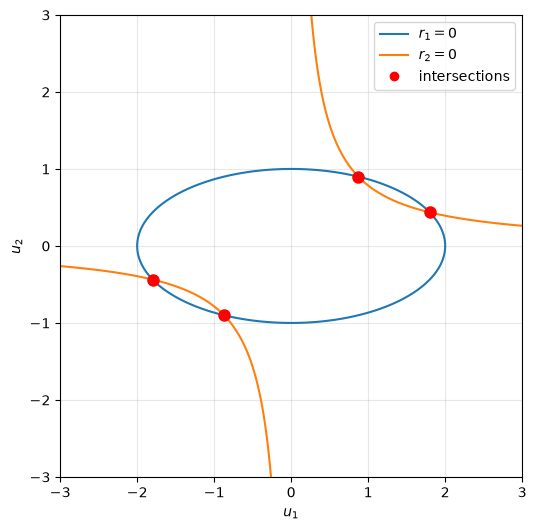

In [ ]:
u1_grid, u2_grid = np.meshgrid(np.linspace(-3, 3, 600), np.linspace(-3, 3, 600))
R = residuals([u1_grid, u2_grid])   # plot the residual lines

fig, ax = plt.subplots(figsize=(6, 6))
c1 = ax.contour(u1_grid, u2_grid, R[0], levels=[0], colors="tab:blue")
c2 = ax.contour(u1_grid, u2_grid, R[1], levels=[0], colors="tab:orange")

# plot the intersection points that were previusly calculated
ax.plot(u1[0], u1[1], "ro", ms=8)
ax.plot(u2[0], u2[1], "ro", ms=8)
ax.plot(u3[0], u3[1], "ro", ms=8)
ax.plot(u4[0], u4[1], "ro", ms=8)

ax.set_xlabel("$u_1$")
ax.set_ylabel("$u_2$")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(
    handles=[
        plt.Line2D([], [], color="tab:blue", label="$r_1 = 0$"),
        plt.Line2D([], [], color="tab:orange", label="$r_2 = 0$"),
        plt.Line2D([], [], marker="o", color="r", ls="", label="intersections"),
    ]
)
plt.show()


## Results

the results show that the system converges quickly to a solution. there are to be several solutions as seen by the examples given. this makes sense since r1 is an ellipse and r2 is a hyperbola crossing the ellipse there are 4 total points where these functions cross. so there are four solutions in total.

## Interpretation

i learned that doing the calculations by hand is very labor intensive. even when using small "tricks" to quickly calculatie the inverse of a 2x2 matrix. so aside from learning how a newton solver works i also learned that it is very impractical to do by hand and that finding ways to accelerate the calculation of derrivatives and inverses can drasticaly speed up runtimes